# AVAX SHORT — Train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục. Sửa **ô Cấu hình**, rồi chọn **Run All**. `TIMEFRAME` hiện là `5min`; có thể dùng `15min`, `1h`, `4h` hoặc khung cố định khác là bội số của 5 phút. Kết quả lưu thành CSV cạnh notebook.

Bollinger, RSI và replay chiến thuật chạy trên GPU ở fp32; score được tính trên CPU để dễ đổi công thức. Mỗi bộ tham số chỉ giữ một lệnh tại một thời điểm. Đổi `SCORE_FORMULA` rồi chạy lại ô **Tính lại score** để xếp hạng lại kết quả sẵn có mà không chạy lại GPU.

Biến có thể dùng trong công thức: `performance`, `max_dd`, `avg_dd`, `r2`, `number_of_trade`, `r_per_month`, `ulcer_r`, `r_martin_monthly`, `r_sharpe_monthly`. Công thức mặc định giữ đúng notebook train cũ; ví dụ có thể thử `r_martin_monthly` hoặc `r_sharpe_monthly` để xếp hạng theo metric R quy đổi theo tháng.

**Lưu ý:** `MAX_HOLDING_BARS` tính theo số nến của `TIMEFRAME`. Mẫu số phí tự động là số nến trong 8 giờ: `8` cho 1h, `32` cho 15 phút, `96` cho 5 phút, `2` cho 4h.

Ở ô đồ thị cuối, đặt `BACKTEST_START_DATE` và `BACKTEST_END_DATE` để xem trial trên khoảng ngày khác với kỳ train. Để `None` nếu muốn dùng khoảng ngày train; đổi ngày ở ô cuối chỉ replay một trial, không chạy lại toàn bộ grid.


In [1]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2021-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2026-01-01"            # ngày kết thúc, bao gồm ngày này

#START_DATE = "2023-07-01"          # ngày bắt đầu, bao gồm ngày này
#END_DATE = "2025-01-01"            # ngày kết thúc, bao gồm ngày này

# Nếu START_DATE/END_DATE là None, script dùng khoảng mặc định của timeframe đã biết.
DATA_CSV = DATA_CSV = "../data_5m/btcusdt_futures_5min.csv"                     # None = avaxusdt_futures_5min.csv beside this notebook
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

#SCORE_FORMULA = "performance/number_of_trade*r2**5"
#SCORE_FORMULA = "r_martin_monthly"
#SCORE_FORMULA = "r_sharpe_monthly"
SCORE_FORMULA = "performance"
# Sửa trực tiếp các danh sách dưới đây để đổi grid cho TIMEFRAME đang chọn.
# Khi đổi TIMEFRAME, các danh sách này giữ nguyên cho đến khi bạn sửa.
# Số bộ tham số là tích số lượng giá trị trong mỗi danh sách.
# boll_window_dev có thể là mảng nhiều giá trị, ví dụ [1.7, 1.8, 2.0].
SEARCH_SPACES = {
    "boll_window": [6, 8, 10, 12, 14, 16],
    "boll_window_dev": [1.7, 1.8, 1.9, 2.0, 2.1, 2.2, 2.3],
    "rsi_window": [35, 40, 50, 60, 70, 80, 90, 100, 120],
    "rsi_threshold": [35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49],
    "sl_multiplier": [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288
FEE_BARS = None                    # None = mặc định của script
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 5 = kiểm tra 5 bộ
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook


In [2]:
# Nạp file GPU cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục crypto)
from pathlib import Path
import importlib.util
import itertools
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "short_bollinger+RSI"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "refference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_short_train_full_grid_gpu", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = (Path(DATA_CSV).expanduser().resolve() if DATA_CSV
            else script_path.with_name("avaxusdt_futures_5min.csv"))
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)


CSV: C:\Users\Legion\Desktop\TradingProject\reference\data_5m\btcusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI\train_full_grid_gpu.py


In [3]:
# Đọc dữ liệu 5 phút, resample và tạo grid
strategy.timeframe_offset(TIMEFRAME)
default_start, default_end = strategy.default_range(TIMEFRAME)
start_date = START_DATE or default_start
end_date = END_DATE or default_end
expected_keys = set(strategy.search_space(TIMEFRAME))
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())


Dữ liệu: 175,392 nến; 2021-01-01 00:00:00 → 2026-01-01 23:45:00
Grid: 102,060 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio
0,6,1.7,35,35,0.3,1.1
1,6,1.7,35,35,0.4,1.1
2,6,1.7,35,35,0.5,1.1
3,6,1.7,35,35,0.6,1.1
4,6,1.7,35,35,0.7,1.1


In [4]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")


c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Thời gian: {'indicators_and_transfer_s': 1.0872916000080295, 'total_gpu_s': 11.461891800019657}
Đã tính 102,060 bộ tham số


In [5]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = result.copy()
result["score"] = strategy.apply_score_formula(result, SCORE_FORMULA)
result["score_formula"] = SCORE_FORMULA
print("Score:", SCORE_FORMULA)


Score: performance


In [6]:
# Tùy chọn: đối chiếu mẫu với bản CPU fp32
if VERIFY_SAMPLES:
    strategy.verify_samples(
        bars, result, TIMEFRAME, VERIFY_SAMPLES,
        MAX_HOLDING_BARS, SCORE_FORMULA, FEE_BARS,
    )


In [7]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_fp32_{TIMEFRAME}.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

#ranked = result.dropna(subset=["score"]).sort_values("score", ascending=False)
ranked = result.loc[(result["number_of_trade"] > 30) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))


Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI\full_gpu_grid_results_fp32_15min.csv
Bộ có score hợp lệ: 96,431/102,060


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,score,score_formula
85326,16,1.7,40,35,0.9,1.1,38.496826,11.890000,3.31,0.838770,329,0.641341,4.520701,0.141868,0.268903,38.496826,performance
68370,14,1.7,40,38,0.9,1.1,38.271568,15.490000,4.12,0.812570,599,0.637588,5.587714,0.114105,0.192561,38.271568,performance
30160,8,2.2,60,45,1.3,1.1,37.213100,12.920000,3.83,0.862035,611,0.619955,5.012661,0.123678,0.183378,37.213100,performance
85052,16,1.7,35,35,0.5,1.1,36.532719,13.630000,3.58,0.893121,530,0.608620,4.661571,0.130561,0.196208,36.532719,performance
68082,14,1.7,35,37,0.9,1.1,36.376793,14.800000,4.56,0.747526,620,0.606022,6.247317,0.097005,0.182953,36.376793,performance
87772,16,1.8,40,36,0.7,1.1,36.371487,12.700000,3.23,0.896377,424,0.605934,4.897121,0.123733,0.213670,36.371487,performance
29872,8,2.2,50,44,1.3,1.1,36.357162,16.020000,4.32,0.854823,602,0.605695,5.735381,0.105607,0.182506,36.357162,performance
21713,8,1.8,120,41,0.8,1.1,36.192692,9.220000,2.31,0.881795,214,0.602955,2.205081,0.273439,0.293017,36.192692,performance
63780,12,2.2,50,38,0.9,1.1,35.614964,9.730000,3.38,0.876227,324,0.593330,3.851371,0.154057,0.240895,35.614964,performance
51032,12,1.7,35,35,0.5,1.1,35.570965,16.850000,6.55,0.509876,579,0.592597,8.593904,0.068956,0.187096,35.570965,performance


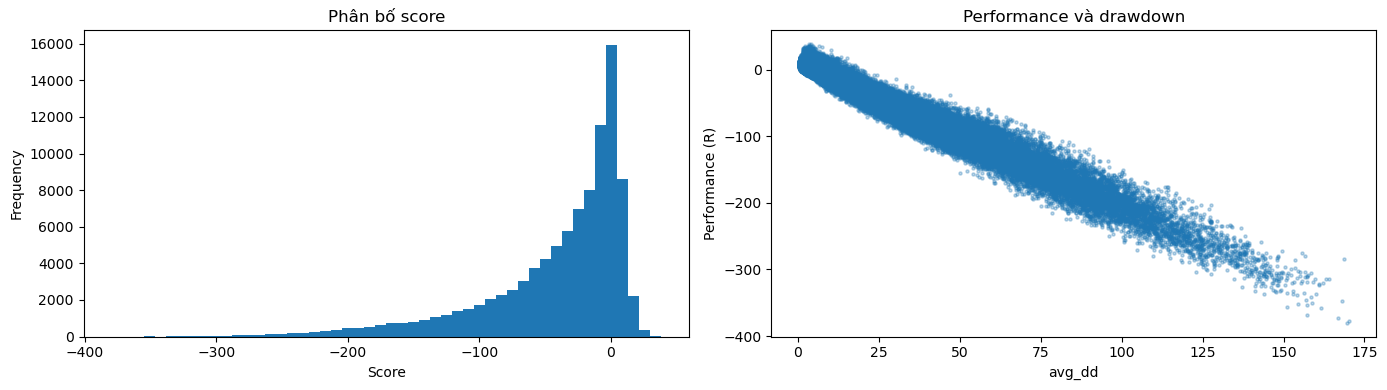

In [8]:
# Biểu đồ để xem phân bố score và hiệu quả/rủi ro của grid
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    drawdown = "max_dd" if "max_dd" in SCORE_FORMULA else "avg_dd"
    axes[1].scatter(ranked[drawdown], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel=drawdown, ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()


c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))
c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Giai đoạn backtest: 2021-01-01 00:00:00 đến 2026-10-01 23:45:00


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,score,score_formula
backtest_trial,14,2.2,120,43,1.2,1.1,27.343941,7.54,1.77,0.957684,285,0.396318,2.282691,0.173619,0.195751,27.343941,performance


Trial 82503: 285 lệnh; performance từ lệnh = 27.343944 R; backtest GPU = 27.343941 R


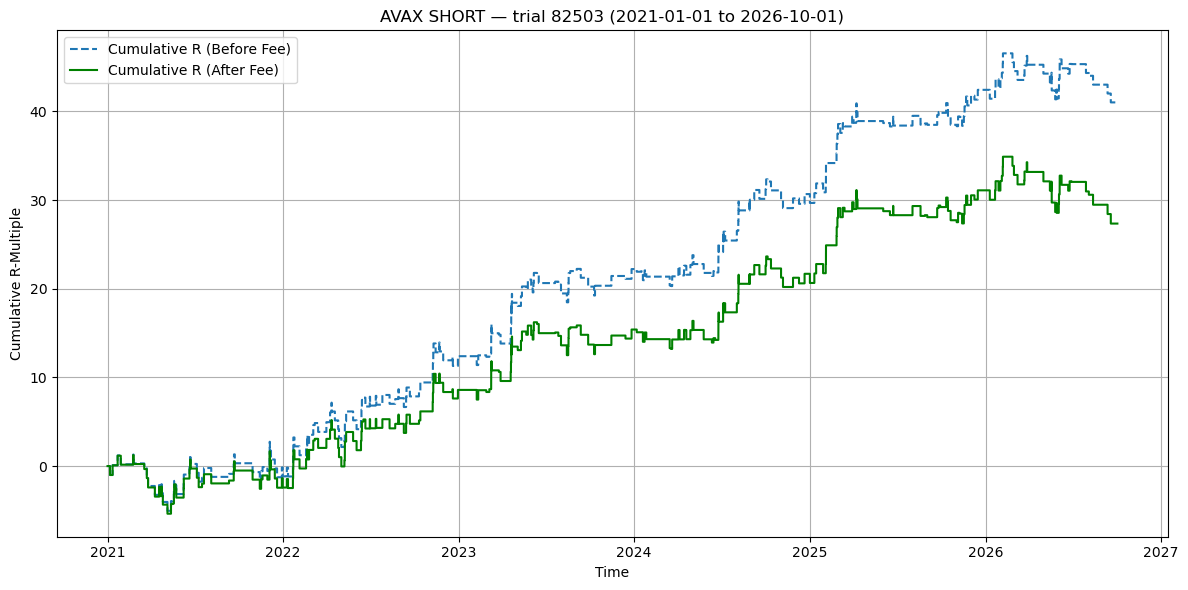

In [9]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này.

TRIAL_ID = 82503 

BACKTEST_START_DATE = "2021-01-01"  # Ví dụ "2024-03-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-10-01"    # Ví dụ "2024-06-30"; None = ngày kết thúc train

import math
import numpy as np
import pandas as pd
from numba import cuda


@cuda.jit
def _trace_selected_trial(close, high, low, upper, lower, rsi, direction,
                          rsi_window, threshold, multiplier, ratio,
                          max_holding_bars, fee_bars, entry_indices,
                          exit_indices, entry_prices, stop_prices, targets,
                          gross_returns, entry_fees, holding_fees, wins,
                          trade_count):
    if cuda.grid(1) != 0:
        return
    zero = np.float32(0)
    one = np.float32(1)
    n = close.size
    i = max(rsi_window, 1)
    count = 0
    while i < n - 1:
        if direction == 1:
            signal = (close[i - 1] < upper[0, i] and close[i] > upper[0, i]
                      and rsi[0, i] > threshold)
        else:
            signal = (close[i - 1] > lower[0, i] and close[i] < lower[0, i]
                      and rsi[0, i] < threshold)
        if signal:
            entry = close[i]
            if direction == 1:
                risk = (entry - lower[0, i]) * multiplier
            else:
                risk = (upper[0, i] - entry) * multiplier
            if entry > zero and risk > zero:
                sl_price_ratio = risk / entry
                entry_fee = np.float32(0.001) / sl_price_ratio
                if entry_fee <= np.float32(0.2):
                    if direction == 1:
                        stop = entry - risk
                        target = entry + ratio * risk
                    else:
                        stop = entry + risk
                        target = entry - ratio * risk
                    j = i + 1
                    while j < n:
                        holding = j - i
                        if holding >= max_holding_bars:
                            gross = ((close[j] - entry) / risk if direction == 1
                                     else (entry - close[j]) / risk)
                            win = 1
                            break
                        if direction == 1:
                            hit_stop = low[j] <= stop
                            hit_target = high[j] >= target
                        else:
                            hit_stop = high[j] > stop
                            hit_target = low[j] < target
                        if hit_stop:
                            gross = -one
                            win = 0
                            break
                        if hit_target:
                            gross = ratio
                            win = 1
                            break
                        if j == n - 1:
                            gross = ((close[j] - entry) / risk if direction == 1
                                     else (entry - close[j]) / risk)
                            win = 1
                            break
                        j += 1
                    holding_fee = (np.float32(0.0001) *
                                   (np.float32(holding) / fee_bars) / sl_price_ratio)
                    entry_indices[count] = i
                    exit_indices[count] = j
                    entry_prices[count] = entry
                    stop_prices[count] = stop
                    targets[count] = target
                    gross_returns[count] = gross
                    entry_fees[count] = entry_fee
                    holding_fees[count] = holding_fee
                    wins[count] = win
                    count += 1
                    i = j + 1  # Không vào lệnh mới trên nến vừa thoát.
                    continue
        i += 1
    trade_count[0] = count


def plot_r_multiple_pnl(trades):
    """Đường R tích lũy trước và sau phí, cùng dạng với test 15min."""
    ordered = trades.sort_values("close_timestamp").reset_index(drop=True)
    gross = ordered["tp_sl_ratio"].where(ordered["win_lose"], -1.0)
    net = gross - ordered["fee_risk_ratio"]
    times = [ordered["close_timestamp"].iloc[0]]
    before = [0.0]
    after = [0.0]
    for timestamp, r_gross, r_net in zip(ordered["close_timestamp"], gross, net):
        times.extend((timestamp, timestamp))
        before.extend((before[-1], before[-1] + r_gross))
        after.extend((after[-1], after[-1] + r_net))
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.step(times, before, label="Cumulative R (Before Fee)", linestyle="--", where="post")
    ax.step(times, after, label="Cumulative R (After Fee)", color="green", where="post")
    ax.set(xlabel="Time", ylabel="Cumulative R-Multiple",
           title=f"AVAX {'LONG' if direction == 1 else 'SHORT'} — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()


if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
trial = result.loc[TRIAL_ID]
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))
# Chỉ chạy lại một bộ tham số trên khoảng backtest; không train lại toàn bộ grid.
selected_grid = grid.loc[[TRIAL_ID]].reset_index(drop=True)
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, selected_grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
backtest_trial = backtest_result.iloc[0]
direction = 1 if SIDE_FOLDER.startswith("long_") else -1
fee_bars = FEE_BARS
if fee_bars is None:
    fee_bars = strategy.fee_holding_divisor(TIMEFRAME)
if fee_bars <= 0:
    raise ValueError("FEE_BARS phải lớn hơn 0")

# Tính chỉ báo cho đúng bộ tham số bằng các kernel GPU đang dùng trong grid.
n = len(backtest_bars)
close32 = np.ascontiguousarray(backtest_bars["close"].to_numpy(dtype=np.float32))
high32 = np.ascontiguousarray(backtest_bars["high"].to_numpy(dtype=np.float32))
low32 = np.ascontiguousarray(backtest_bars["low"].to_numpy(dtype=np.float32))
d_close = cuda.to_device(close32)
d_high = cuda.to_device(high32)
d_low = cuda.to_device(low32)
d_upper = cuda.device_array((1, n), dtype=np.float32)
d_lower = cuda.device_array((1, n), dtype=np.float32)
d_rsi = cuda.device_array((1, n), dtype=np.float32)
d_boll_window = cuda.to_device(np.array([int(trial["boll_window"])], dtype=np.int32))
d_boll_deviation = cuda.to_device(np.array([trial["boll_window_dev"]], dtype=np.float32))
d_rsi_window = cuda.to_device(np.array([int(trial["rsi_window"])], dtype=np.int32))
boll_kernel = (strategy._bollinger_bands if direction == 1
               else strategy._bollinger_windows)
boll_kernel[(n + 127) // 128, 128](
    d_close, d_boll_window, d_boll_deviation, d_upper, d_lower)
strategy._rsi_windows[1, 32](d_close, d_rsi_window, d_rsi)

entry_indices = cuda.device_array(n, dtype=np.int32)
exit_indices = cuda.device_array(n, dtype=np.int32)
entry_prices = cuda.device_array(n, dtype=np.float32)
stop_prices = cuda.device_array(n, dtype=np.float32)
targets = cuda.device_array(n, dtype=np.float32)
gross_returns = cuda.device_array(n, dtype=np.float32)
entry_fees = cuda.device_array(n, dtype=np.float32)
holding_fees = cuda.device_array(n, dtype=np.float32)
wins = cuda.device_array(n, dtype=np.int32)
trade_count = cuda.device_array(1, dtype=np.int32)
_trace_selected_trial[1, 1](
    d_close, d_high, d_low, d_upper, d_lower, d_rsi, direction,
    int(trial["rsi_window"]), np.float32(trial["rsi_threshold"]),
    np.float32(trial["sl_multiplier"]), np.float32(trial["tp_sl_ratio"]),
    MAX_HOLDING_BARS, np.float32(fee_bars), entry_indices,
    exit_indices, entry_prices, stop_prices, targets, gross_returns,
    entry_fees, holding_fees, wins, trade_count)
count = int(trade_count.copy_to_host()[0])
if count != int(backtest_trial["number_of_trade"]):
    raise AssertionError(f"Trial {TRIAL_ID}: backtest GPU có {backtest_trial['number_of_trade']} lệnh, replay có {count}")

entries = entry_indices.copy_to_host()[:count]
exits = exit_indices.copy_to_host()[:count]
prices = entry_prices.copy_to_host()[:count]
stops = stop_prices.copy_to_host()[:count]
take_profits = targets.copy_to_host()[:count]
gross = gross_returns.copy_to_host()[:count]
entry_costs = entry_fees.copy_to_host()[:count]
holding_costs = holding_fees.copy_to_host()[:count]
won = wins.copy_to_host()[:count]
timestamps = backtest_bars["timestamp"].to_numpy()

records = [{
    "entry_price": np.nan, "stop_loss": np.nan, "take_profit": np.nan,
    "tp_sl_ratio": 0.0, "fee_risk_ratio": 0.0, "win_lose": True,
    "open_timestamp": timestamps[0], "close_timestamp": timestamps[0],
}]
for k in range(count):
    records.append({
        "entry_price": float(prices[k]),
        "stop_loss": float(stops[k]),
        "take_profit": float(take_profits[k]),
        "tp_sl_ratio": float(gross[k] if won[k] else np.float32(trial["tp_sl_ratio"])),
        "fee_risk_ratio": float(entry_costs[k] + holding_costs[k]),
        "win_lose": bool(won[k]),
        "open_timestamp": timestamps[entries[k]],
        "close_timestamp": timestamps[exits[k]],
    })
records.append({
    "entry_price": np.nan, "stop_loss": np.nan, "take_profit": np.nan,
    "tp_sl_ratio": 0.0, "fee_risk_ratio": 0.0, "win_lose": True,
    "open_timestamp": timestamps[-1], "close_timestamp": timestamps[-1],
})
df = pd.DataFrame(records)
net_r = df["tp_sl_ratio"].where(df["win_lose"], -1.0) - df["fee_risk_ratio"]
if not np.isclose(net_r.sum(), float(backtest_trial["performance"]), rtol=1e-4, atol=1e-3):
    raise AssertionError(f"Trial {TRIAL_ID}: tổng R từ lệnh khác performance của backtest GPU")
print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
display(backtest_trial.to_frame(name="backtest_trial").T)
print(f"Trial {TRIAL_ID}: {count} lệnh; performance từ lệnh = {net_r.sum():.6f} R; "
      f"backtest GPU = {backtest_trial['performance']:.6f} R")
plot_r_multiple_pnl(df)


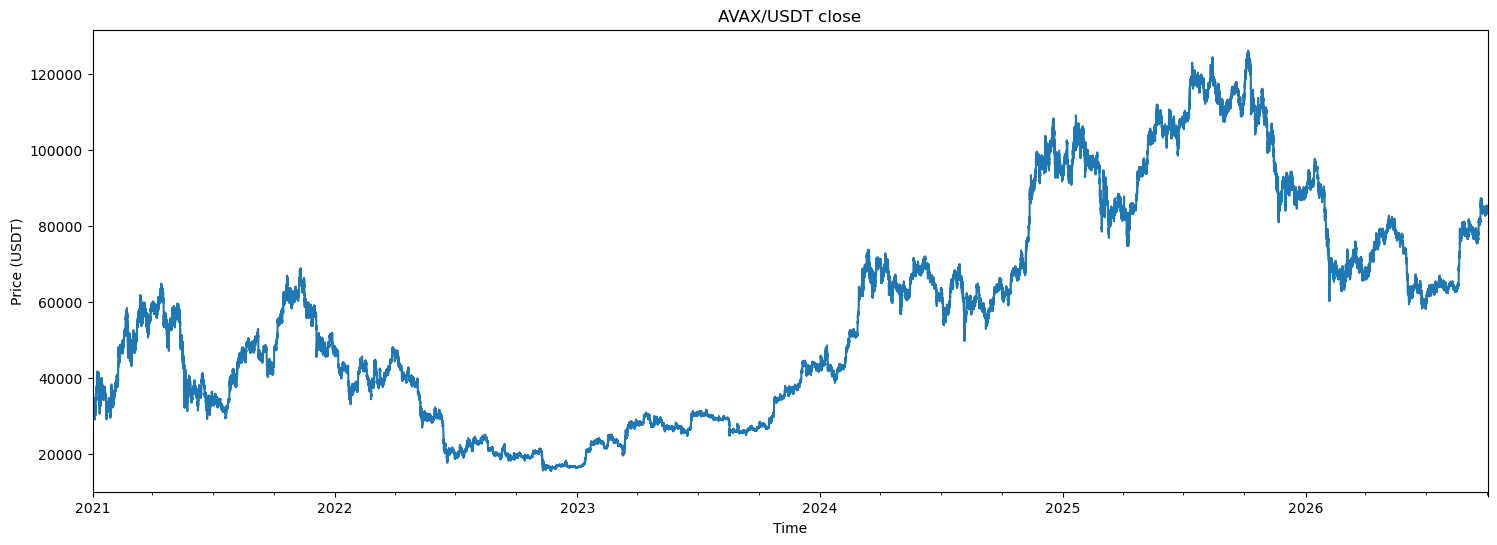

In [10]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()